# Log stream engine: report

This notebook runs the pipeline from the `log_engine` package on `data/*.log` and charts the results. All pipeline logic lives in the `.py` modules; the notebook only calls it.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import tracemalloc
from collections import defaultdict
import matplotlib.pyplot as plt
from log_engine.aggregation import Stats, blacklist_report, count_items, detect_brute_force
from log_engine.ingestion import load_blacklist, read_sources
from log_engine.pipeline import build_pipeline
from log_engine.rules import RULES, check_rules

## 1. One streaming pass

Every stage is a lazy iterator. `detect_brute_force` pulls records through all stages one at a time.

In [2]:
tracemalloc.start()
blacklist = load_blacklist('data/blacklist.txt')
read, stats, findings, hits, cycles = [0, 0], Stats(), defaultdict(list), defaultdict(int), []
records = check_rules(stats.tally(build_pipeline(count_items(read_sources('data/auth.log', 'data/net.log'), read))), RULES, findings, hits, blacklist=blacklist)
alerts = list(detect_brute_force(records, 5, cycles))
peak = tracemalloc.get_traced_memory()[1]
tracemalloc.stop()
print(f'read {read[0]}, accepted {stats.accepted}, rejected {read[0] - read[1] - stats.accepted}, blank {read[1]}, peak memory {peak/1024:.0f} KiB')

read 10000, accepted 9313, rejected 385, blank 302, peak memory 113 KiB


## 2. Counts per level, kind and user (`defaultdict`)

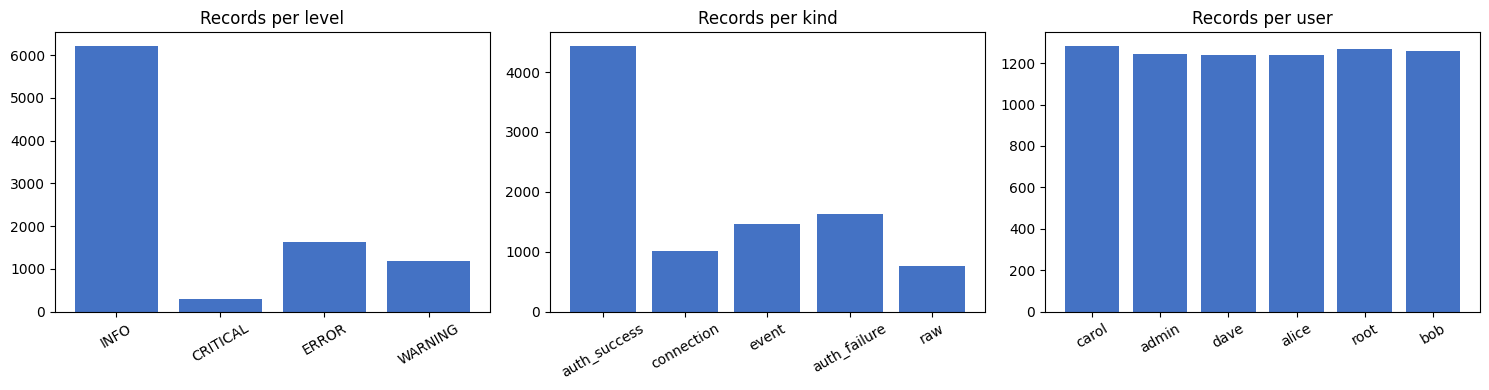

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, data) in zip(axes, [('Level', stats.by_level), ('Kind', stats.by_kind), ('User', stats.by_user)]):
    ax.bar(list(data), list(data.values()), color='#4472c4')
    ax.set_title(f'Records per {title.lower()}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 3. Blacklist (`frozenset`) against active IPs (`set`)

In [4]:
for name, ips in blacklist_report(blacklist, stats.active_ips).items():
    print(f'{name:<22} {len(ips):>3}  {sorted(ips)[:4]}')
print('IPs with errors:', len(stats.error_ips))

union                   33  ['10.0.0.1', '10.0.0.10', '10.0.0.11', '10.0.0.12']
intersection             2  ['198.51.100.23', '203.0.113.7']
active_not_listed       30  ['10.0.0.1', '10.0.0.10', '10.0.0.11', '10.0.0.12']
listed_dormant           1  ['172.16.0.99']
symmetric_difference    31  ['10.0.0.1', '10.0.0.10', '10.0.0.11', '10.0.0.12']
IPs with errors: 32


## 4. Brute-force alerts and rule findings

10 alerts over 11 cycles; last cycle validated: True
  10.0.0.12: 5 consecutive failures
  203.0.113.7: 5 consecutive failures
  10.0.0.1: 5 consecutive failures
  10.0.0.26: 5 consecutive failures
  203.0.113.7: 5 consecutive failures
  10.0.0.3: 5 consecutive failures
  203.0.113.7: 5 consecutive failures
  203.0.113.7: 5 consecutive failures
  10.0.0.29: 5 consecutive failures
  10.0.0.23: 5 consecutive failures


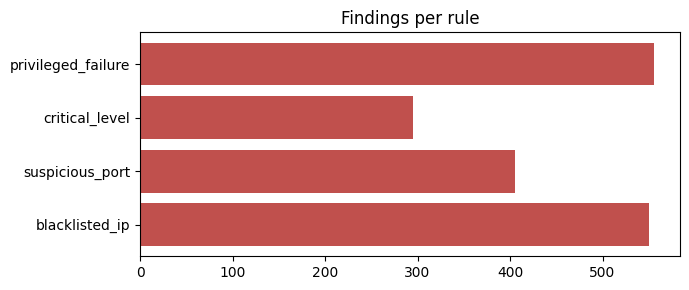

In [5]:
print(f'{len(alerts)} alerts over {len(cycles)} cycles; last cycle validated: {cycles[-1]}')
for ip, n in alerts:
    print(f'  {ip}: {n} consecutive failures')
plt.figure(figsize=(7, 3))
plt.barh(list(hits), list(hits.values()), color='#c0504d')
plt.title('Findings per rule')
plt.tight_layout()
plt.show()

## 5. Memory stays flat as input grows

Peak memory for the simulated stream at several sizes. A list-based load would grow linearly.

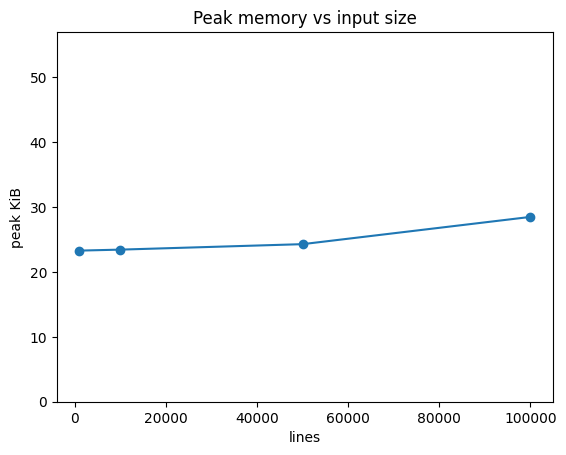

['23 KiB', '23 KiB', '24 KiB', '28 KiB']


In [6]:
from log_engine.simulator import simulate
sizes, peaks = [1_000, 10_000, 50_000, 100_000], []
for n in sizes:
    tracemalloc.start()
    list(detect_brute_force(Stats().tally(build_pipeline(simulate(n)))))
    peaks.append(tracemalloc.get_traced_memory()[1] / 1024)
    tracemalloc.stop()
plt.plot(sizes, peaks, marker='o')
plt.xlabel('lines'); plt.ylabel('peak KiB'); plt.title('Peak memory vs input size')
plt.ylim(0, max(peaks) * 2)  # axis from 0: a flat line must look flat
plt.show()
print([f'{p:.0f} KiB' for p in peaks])